# AR(3): repeated order-selection experiment with padded warm starts

The same 50 Jones-sampled AR(3) coefficient vectors and 2,000-observation series are used for two fresh fits. Each dimension receives three starts and 500 geometric-schedule iterations. In the warm-start fit, the first random direction is replaced, for every dimension k >= 2, by the previous best direction with one zero appended. The other two random starts, observation windows, and optimization settings are unchanged.

The original saved curves remain available as a historical reference. A fresh independent-start control is included because the current optimizer does not exactly reproduce the older cached widths. All returned widths are feasible search results; monotonicity does not certify global optimality.

Data and figures are saved under `outputs/csv/ar3_order_selection_warm_starts/`, `outputs/images/ar3_order_selection_warm_starts/`, and `outputs/pdfs/ar3_order_selection_warm_starts/`. Raw series and both sets of fitted directions are retained. Re-execution reuses completed per-process checkpoints with matching settings.


In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

PROJECT_ROOT = next(root for root in (Path.cwd(), *Path.cwd().parents)
                    if (root / "Code/Code_AR_processes/ar3_order_selection_warm_starts.py").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from Code.Code_AR_processes.ar3_order_selection_warm_starts import (
    run_experiment, DATA_DIR, IMAGE_DIR, VARIANTS,
)


In [2]:
data_dir = run_experiment()



Correct selections out of 50:
variant                   Independent rerun  Original saved  Padded warm start
method                                                                        
Descent chain                           NaN             NaN               19.0
First difference                        7.0             9.0                9.0
Perron first difference                 6.0             8.0                8.0
Perron second difference                9.0            12.0               12.0
Second difference                      11.0            15.0               15.0

Curves with upward steps:
variant
Independent rerun    47
Original saved       45
Padded warm start     0


Matplotlib is building the font cache; this may take a moment.


## Order-selection comparison

Entries below are correct selections out of 50. The first two columns separate the historical saved results from the fresh control. The descent-chain score is evaluated on the monotone warm-start curves only; a missing baseline entry means that method was not evaluated on that nonmonotone variant.


variant,Original saved,Independent rerun,Padded warm start
method,,,
Descent chain,<NA>,<NA>,19
First difference,9,7,9
Perron first difference,8,6,8
Perron second difference,12,9,12
Second difference,15,11,15


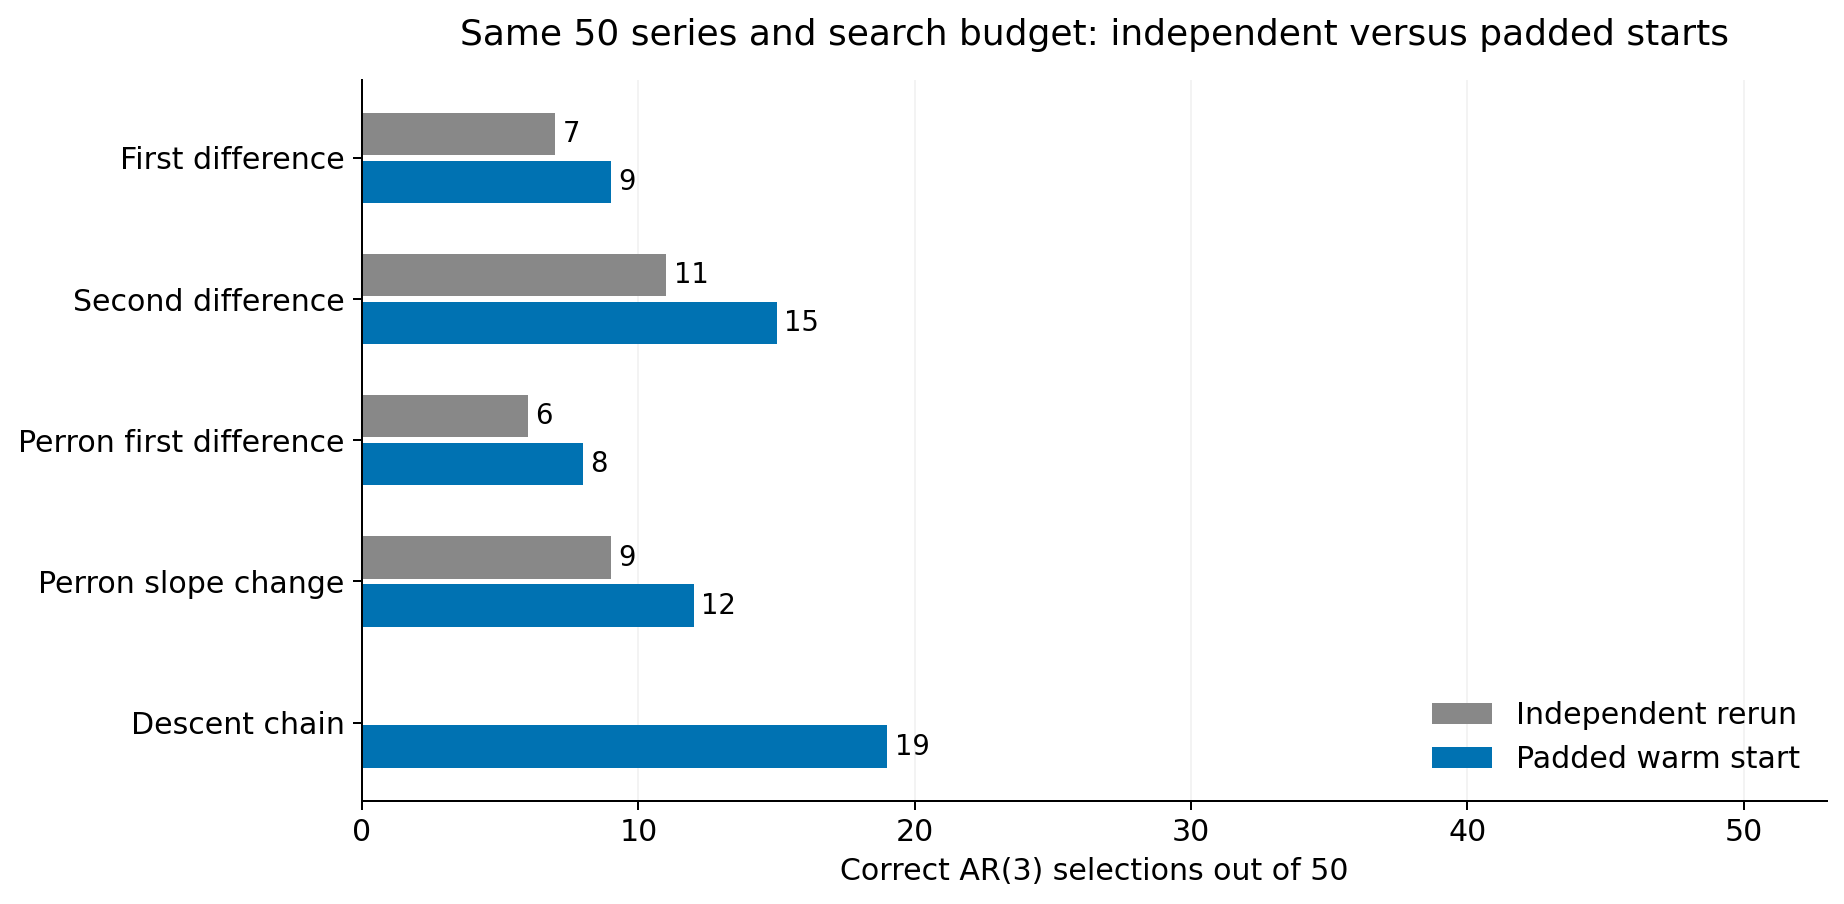

In [3]:
summary = pd.read_csv(DATA_DIR / "summary.csv")
accuracy = summary.pivot(index="method", columns="variant", values="correct")
accuracy = accuracy.reindex(columns=VARIANTS).astype("Int64")
display(accuracy)
display(Image(filename=str(IMAGE_DIR / "selector_accuracy_comparison.png")))


## Monotonicity and example curves

The diagnostic uses an upward-step tolerance of 1e-12. The raw optimizer outputs are saved without smoothing. Re-evaluating a zero-padded dot product can change the width by a few units of floating-point roundoff; the descent-chain calculation treats only machine-precision-sized drops as zero, as recorded in `numerical_notes.json`.


,processes,nonmonotone_curves,maximum_increase
variant,,,
Original saved,50,45,3.324769e-01
Independent rerun,50,47,4.290084e-01
Padded warm start,50,0,3.552714e-15


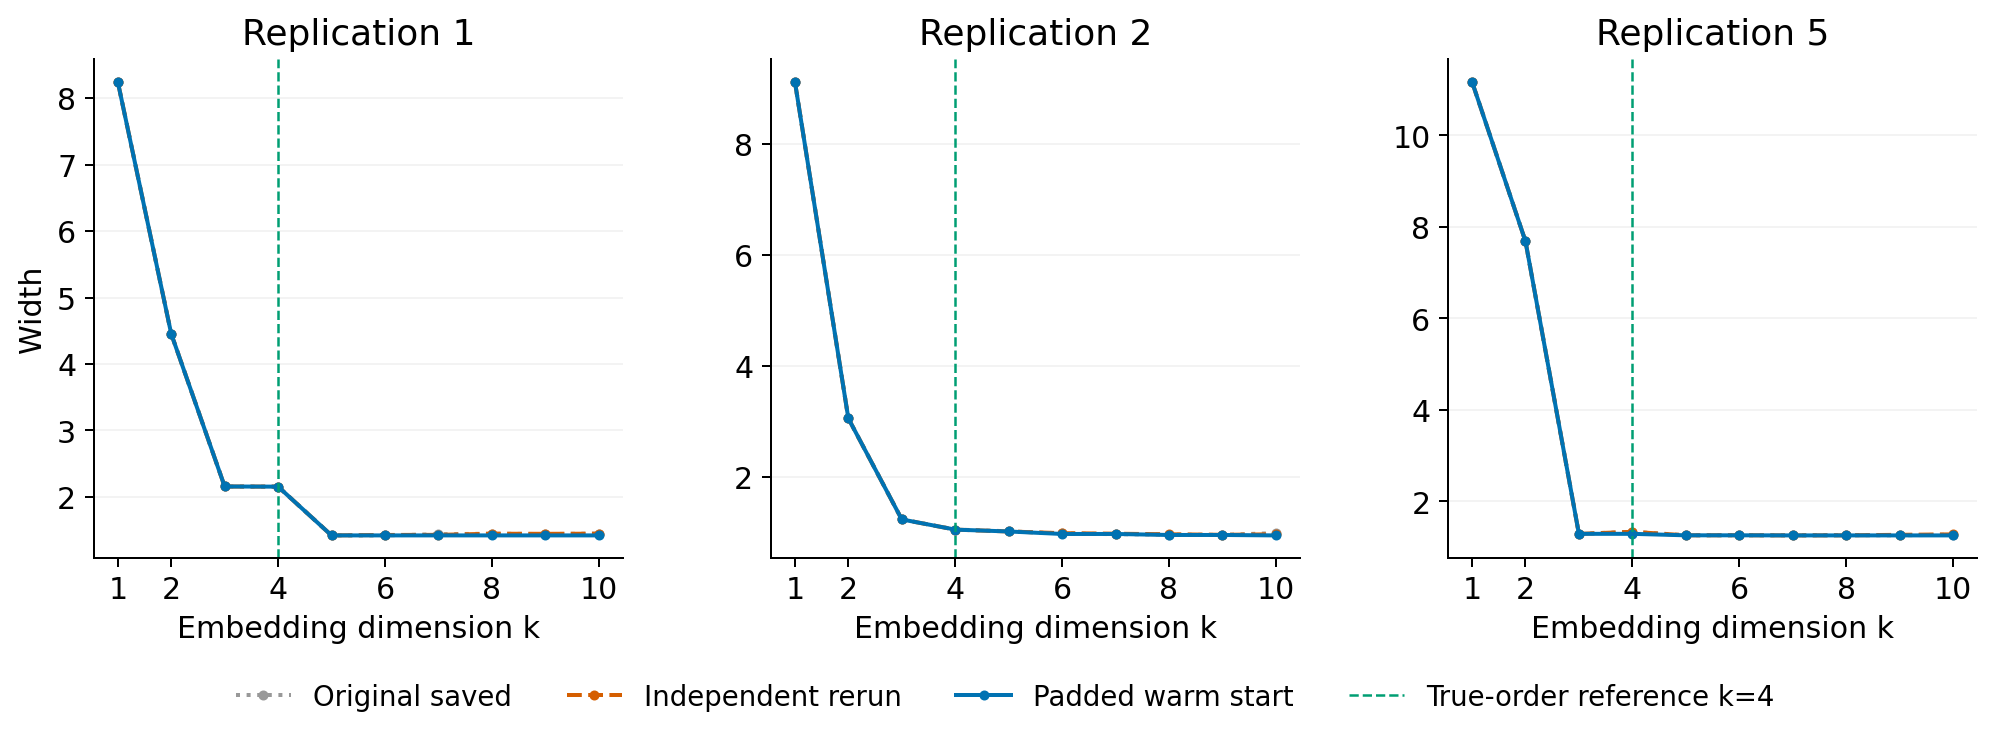

In [4]:
diagnostics = pd.read_csv(DATA_DIR / "monotonicity_diagnostics.csv")
monotonicity = diagnostics.assign(nonmonotone=diagnostics.upward_steps > 0).groupby("variant").agg(
    processes=("replication", "count"),
    nonmonotone_curves=("nonmonotone", "sum"),
    maximum_increase=("maximum_increase", "max"),
)
display(monotonicity.reindex(VARIANTS))
assert monotonicity.loc["Padded warm start", "nonmonotone_curves"] == 0
display(Image(filename=str(IMAGE_DIR / "example_width_curves.png")))


## Saved data and interpretation

`processes/process_001.csv` through `process_050.csv` contain the regenerated series. `replications/replication_001.csv` through `replication_050.csv` contain both fresh fits, including every fitted direction. `width_curves.csv`, `paired_width_comparison.csv`, `selections.csv`, and `summary.csv` contain the combined comparison. `descent_chain_scores.csv` retains all drop weights, stationary probabilities, and selector scores.

The first- and second-difference and Perron rules match `ar3_implied_support_width.ipynb`. The descent-chain rule follows Definition 1.2.10 and Equation (1.6), pp. 5–6, of `/Users/iljasukhanov/Downloads/elbow_point_selection_preview.pdf`. Its population correctness and conditional consistency results do not certify these finite numerical fits.


In [5]:
print("Saved series:", len(list((DATA_DIR / "processes").glob("process_*.csv"))))
print("Saved paired fit checkpoints:", len(list((DATA_DIR / "replications").glob("replication_*.csv"))))
display(summary[summary.variant == "Padded warm start"][["method", "correct", "under", "over", "total"]])


Saved series: 50
Saved paired fit checkpoints: 50


,method,correct,under,over,total
8,First difference,9,41,0,50
9,Second difference,15,35,0,50
10,Perron first difference,8,42,0,50
11,Perron second difference,12,38,0,50
12,Descent chain,19,6,25,50
